# AI - Theory To Practice CA1

### 1.1 Dateset Requirements:
1. 1,000 observations
2. 10 input variables before cleaning
3. Both Numerical & Categorical variables
4. Publicly accessible source - https://www.basketball-reference.com/players/c/curryst01/gamelog/2010

In [112]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [113]:
steph = pd.read_excel("Steph_curry.xlsx")
print("Data Shape:", steph.shape)

Data Shape: (1444, 34)


### 1.2 Problem Definition
- The objective of this project for our models to predict if Stephen Curry can score more than 24.8 points against certain teams, based on his career against each team. 
- This is a Classification Problem, We want a percentage probability result.
- The Target Variable is PTS. (PTS)
- The Predictor Variables are Opp (Opponent), FG%(Field Goal Percentage), eFG%(Effective Field Goal Percentage), TOV(Turnover).
- This project is useful for Sports fans, Gambling Sites, Valuable Insights and potential Investment opportunites.

In [114]:
features = steph[["Date", "Opp", "FG%", "eFG%","FT", "TOV","GmSc", "+/-"]]

In [115]:
steph.head()

,Rk,Gcar,Gtm,Date,Team,Unnamed: 5,Opp,Result,GS,MP,...,DRB,TRB,AST,STL,BLK,TOV,PF,PTS,GmSc,+/-
0,1.0,1.0,1.0,2009-10-28,GSW,NaN,HOU,"L, 107-108",*,"1 day, 11:39:00",...,1.0,2.0,7.0,4.0,0.0,2.0,2.0,14.0,15.5,7.0
1,2.0,2.0,2.0,2009-10-30,GSW,@,PHO,"L, 101-123",*,"1 day, 15:05:00",...,2.0,2.0,4.0,1.0,0.0,3.0,5.0,12.0,7.1,-19.0
2,3.0,3.0,3.0,2009-11-04,GSW,NaN,MEM,"W, 113-105",*,"1 day, 4:27:00",...,5.0,5.0,9.0,2.0,0.0,1.0,4.0,7.0,11.2,-4.0
3,4.0,4.0,4.0,2009-11-06,GSW,NaN,LAC,"L, 90-118",*,21:32:00,...,1.0,1.0,3.0,0.0,0.0,0.0,6.0,5.0,1.5,-13.0
4,5.0,5.0,5.0,2009-11-08,GSW,@,SAC,"L, 107-120",*,"1 day, 7:15:00",...,3.0,4.0,6.0,0.0,0.0,5.0,4.0,9.0,3.4,-5.0


### 2 Data Understanding & Exploratory Data Analysis (EDA)

-  Dataset Size: 1,444 Rows & 36 Columns 

In [116]:
print("Data Shape", steph.shape)

Data Shape (1444, 34)


- Variable Types: 27 Float, 5 String Columns, 1 Datetime & 1 Object

In [117]:
steph.dtypes.value_counts()

float64           27
str                5
datetime64[us]     1
object             1
Name: count, dtype: int64

- Statistical Summary: Quartiles, Mean, Standard Deviation, Min, Max.

In [118]:
features.describe()

,Date,FG%,eFG%,FT,TOV,GmSc,+/-
count,1423,1179.000000,1179.000000,1181.000000,1181.000000,1181.000000,1181.000000
mean,2017-09-02 22:25:53.338018,0.465105,0.573043,4.024555,3.135478,19.339966,6.048264
min,2009-10-28 00:00:00,0.000000,0.000000,0.000000,0.000000,-3.900000,-41.000000
25%,2013-12-30 00:00:00,0.389000,0.469000,2.000000,2.000000,13.100000,-3.000000
50%,2017-06-07 00:00:00,0.467000,0.571000,4.000000,3.000000,19.300000,7.000000
75%,2021-11-18 12:00:00,0.545000,0.676000,6.000000,4.000000,25.200000,16.000000
max,2025-05-06 00:00:00,1.000000,1.300000,18.000000,11.000000,49.200000,44.000000
std,NaN,0.123171,0.160410,3.044624,1.779908,9.080551,14.084679


- Cardinality (Unique Values)

In [119]:
print(features.nunique())

Date    1423
Opp       32
FG%      143
eFG%     288
FT        18
TOV       12
GmSc     364
+/-       76
dtype: int64


- IQR (Inner Quartile Range)

In [120]:
features.select_dtypes(include="number").quantile(0.75) - features.select_dtypes(include="number").quantile(0.25)

FG%      0.156
eFG%     0.207
FT       4.000
TOV      2.000
GmSc    12.100
+/-     19.000
dtype: float64

- Missing Values Summary

In [121]:
missing_features_count = features.isnull().sum()
missing_features_percentage = features.isnull().mean() * 100

missing_features_summary = pd.DataFrame({
    "Missing Count": missing_features_count,
    "Missing Percentage": missing_features_percentage
})

print(missing_features_summary)

      Missing Count  Missing Percentage
Date             21            1.454294
Opp              20            1.385042
FG%             265           18.351801
eFG%            265           18.351801
FT              263           18.213296
TOV             263           18.213296
GmSc            263           18.213296
+/-             263           18.213296


### Average 3 Pointers Made VS Each Team
- Show's us The average amount of 3 pointers scored by Stephen Curry against each team.
- Important as 3 Pointers are what Steph is most known for.
- Potentially some insight into how he will perform based on team.

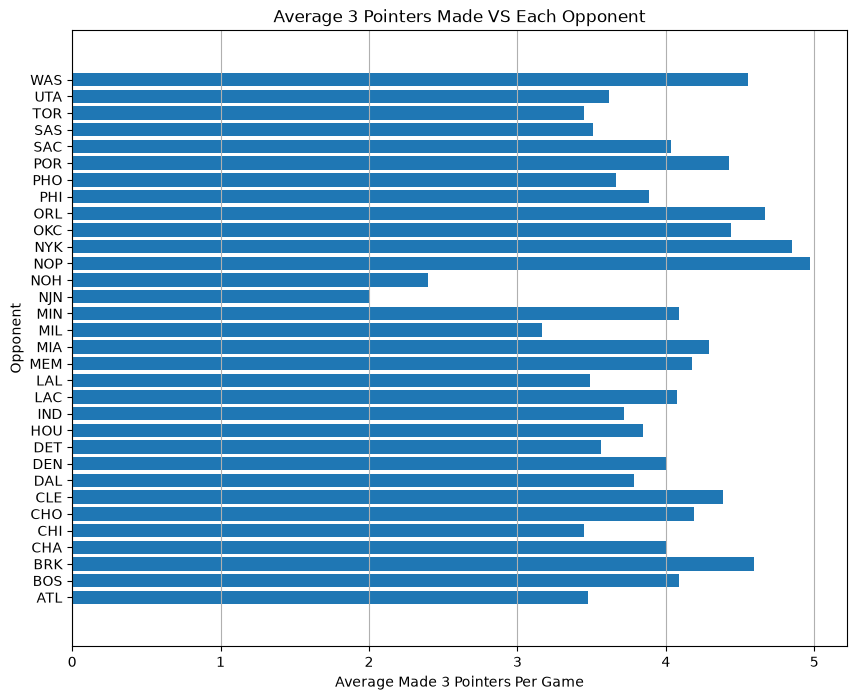

In [122]:
average_fg = steph.groupby("Opp")["3P"].mean()

plt.figure(figsize=(10, 8))
plt.margins(y = 0.08), plt.grid(axis="x")
plt.barh(average_fg.index, average_fg.values)
plt.xlabel("Average Made 3 Pointers Per Game")
plt.ylabel("Opponent")
plt.title("Average 3 Pointers Made VS Each Opponent")

plt.show()

### Average 2 Pointers Made VS Each Team
- Show's us The average amount of 2 pointers scored by Stephen Curry against each team.
- Important as 2 pointers are most common in the sport of Basketball.
- Potentially some insight into how he will perform based on team.

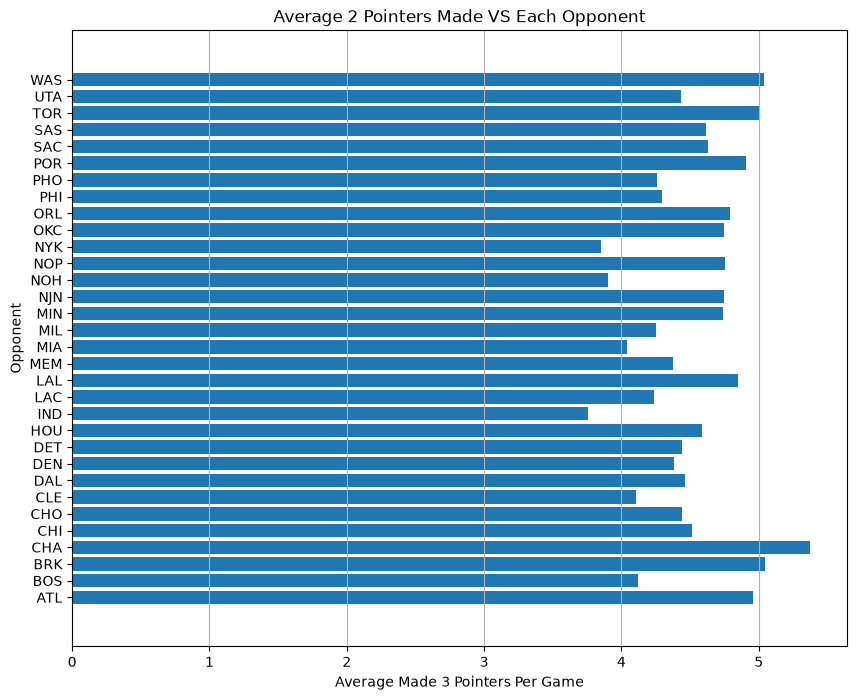

In [123]:
average_fg = steph.groupby("Opp")["2P"].mean()

plt.figure(figsize=(10, 8))
plt.margins(y = 0.08), plt.grid(axis="x")
plt.barh(average_fg.index, average_fg.values)
plt.xlabel("Average Made 3 Pointers Per Game")
plt.ylabel("Opponent")
plt.title("Average 2 Pointers Made VS Each Opponent")

plt.show()

### Average Free Throws Made VS Each Team
- Show's us The average amount of Free Throws scored by Stephen Curry against each team.
- Important as Free Throws are the only other way of scoring.
- Potentially some insight into how he will perform based on team.

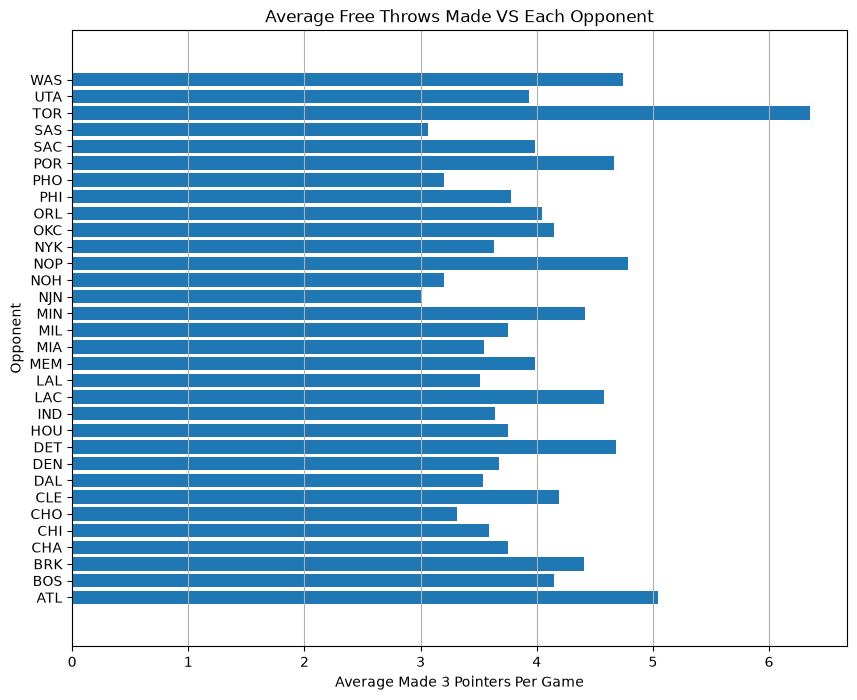

In [124]:
average_fg = steph.groupby("Opp")["FT"].mean()

plt.figure(figsize=(10, 8))
plt.margins(y = 0.08), plt.grid(axis="x")
plt.barh(average_fg.index, average_fg.values)
plt.xlabel("Average Made 3 Pointers Per Game")
plt.ylabel("Opponent")
plt.title("Average Free Throws Made VS Each Opponent")

plt.show()

### Distribution of 3 Pointers Made in Career
- Show's us the distribution of 3 pointers made, throughout Steph's career.
- Important as it shows the distribution of where the 3 pointers are.
- Potentially some insight into how he will perform based performance.

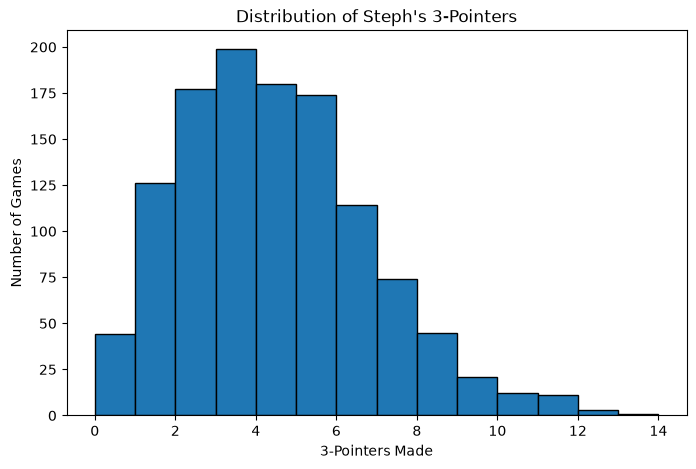

In [125]:
plt.figure(figsize=(8, 5))
plt.hist(steph["3P"], bins=range(
    int(steph["3P"].min()),
    int(steph["3P"].max()) + 2
), edgecolor="black")
plt.xlabel("3-Pointers Made")
plt.ylabel("Number of Games")
plt.title("Distribution of Steph's 3-Pointers")
plt.show()

### Top Field Goal Games
- Show's us The best performances in Steph's Career.
- Important as some of these may be considered outliers.
- Potentially some insight outliers in dataset.

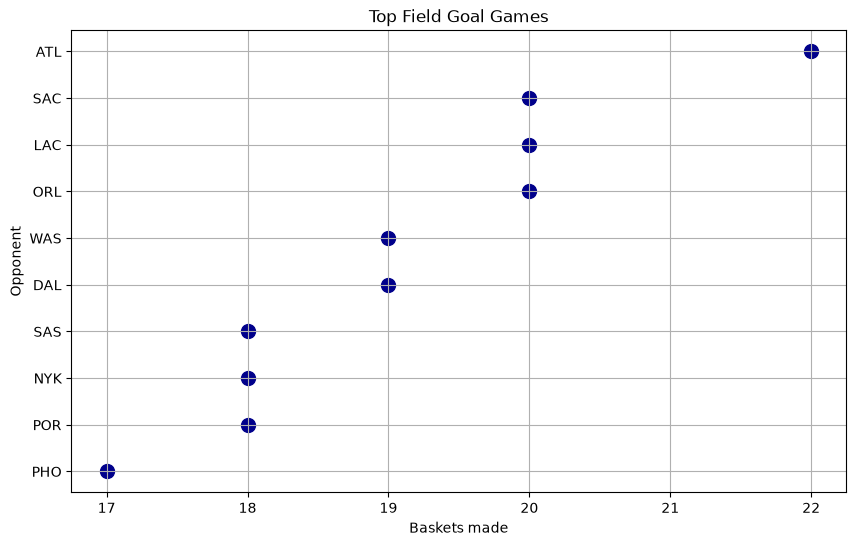

In [126]:
steph.sort_values(by="FG" , ascending=False).head(10).plot(
    kind='scatter', 
    x="FG", 
    y="Opp", 
    figsize=(10, 6),
    grid=True,
    s=100,
    color="darkblue")
plt.title("Top Field Goal Games")
plt.xlabel("Baskets made")
plt.ylabel("Opponent")
plt.gca().invert_yaxis()
plt.show()
